# E-Commerce Customer Churn Analysis

Project Objective : To analyze customer behavior, identify churn patterns, and understand the factor affecting customer retention using python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Data loaded

df = pd.read_csv('ecommerce_churn_raw_15k.csv')

In [3]:
df.head()

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn
0,CUST_100567,2025-05-29,49.0,Mobile Phone,2,7.0,Credit Card,Male,1.0,6,3.0,Married,4.0,2.0,$161.09,0,0
1,CUST_108618,2024-02-29,15.0,Mobile Phone,3,9.0,Credit Card,Male,3.0,7,2.0,Single,12.0,17.0,$327.18,0,0
2,CUST_108036,2022-04-16,39.0,Phone,2,35.0,Debit Card,Female,4.0,5,5.0,Single,8.0,25.0,$289.78,0,0
3,CUST_114773,2023-10-17,1.0,Computer,1,16.0,E Wallet,Male,1.0,3,5.0,Divorced,14.0,2.0,$68.12,1,1
4,CUST_106910,2023-12-11,49.0,Mobile Phone,1,8.0,Debit Card,Female,5.0,1,5.0,Divorced,9.0,21.0,$143.76,1,1


In [5]:
df.shape

(15150, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   CustomerID            15150 non-null  object 
 1   SignupDate            15150 non-null  object 
 2   Tenure                14825 non-null  float64
 3   PreferredLoginDevice  15150 non-null  object 
 4   CityTier              15150 non-null  int64  
 5   WarehouseToHome       14909 non-null  float64
 6   PreferredPaymentMode  15038 non-null  object 
 7   Gender                15150 non-null  object 
 8   HourSpendOnApp        14958 non-null  float64
 9   NumberOfAddress       15150 non-null  int64  
 10  SatisfactionScore     14999 non-null  float64
 11  MaritalStatus         15150 non-null  object 
 12  OrderCount            15150 non-null  float64
 13  DaySinceLastOrder     14938 non-null  float64
 14  CashbackAmount        15150 non-null  object 
 15  Complain           

In [7]:
df.duplicated().sum()

np.int64(150)

In [12]:
df[df.duplicated(keep=False)]

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn
22,CUST_100252,2023-05-13,NaN,Mobile Phone,2,13.0,Credit Card,Male,4.0,7,4.0,Single,10.0,NaN,$316.97,1,1
40,CUST_101403,2022-06-16,13.0,Mobile Phone,2,35.0,COD,Female,3.0,8,4.0,Married,11.0,26.0,$303.06,0,0
53,CUST_102806,2025-05-28,44.0,Phone,2,29.0,COD,M,3.0,8,2.0,Single,5.0,22.0,$261.24,1,1
80,CUST_101594,2022-04-14,39.0,Mobile Phone,2,21.0,Credit Card,Female,2.0,2,3.0,Single,5.0,7.0,$139.87,0,0
82,CUST_102358,2022-04-07,51.0,Phone,2,17.0,Debit Card,Male,5.0,6,1.0,Divorced,3.0,5.0,$337.52,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14678,CUST_114325,2025-09-19,55.0,Mobile Phone,2,17.0,Debit Card,Female,1.0,3,3.0,Divorced,7.0,21.0,$150.75,1,1
14735,CUST_103670,2023-03-29,23.0,Mobile Phone,2,30.0,Cash on Delivery,Male,3.0,9,3.0,Single,9.0,24.0,$72.46,0,0
14817,CUST_101403,2022-06-16,13.0,Mobile Phone,2,35.0,COD,Female,3.0,8,4.0,Married,11.0,26.0,$303.06,0,0
14931,CUST_102885,2023-08-21,50.0,Phone,2,NaN,Debit Card,Female,2.0,1,5.0,Single,5.0,0.0,$319.57,0,0


In [13]:
duplicates_df = df[df.duplicated(keep=False)]
print(duplicates_df.head(10))

      CustomerID  SignupDate  Tenure PreferredLoginDevice  CityTier  \
22   CUST_100252  2023-05-13     NaN         Mobile Phone         2   
40   CUST_101403  2022-06-16    13.0         Mobile Phone         2   
53   CUST_102806  2025-05-28    44.0                Phone         2   
80   CUST_101594  2022-04-14    39.0         Mobile Phone         2   
82   CUST_102358  2022-04-07    51.0                Phone         2   
119  CUST_103685  2023-11-06    59.0         Mobile Phone         2   
134  CUST_106662  2025-07-26    23.0         Mobile Phone         1   
135  CUST_101007  2023-07-15    13.0         Mobile Phone         1   
169  CUST_100150  2024-04-04     8.0                Phone         2   
182  CUST_100170  2022-12-29    13.0             Computer         1   

     WarehouseToHome PreferredPaymentMode  Gender  HourSpendOnApp  \
22              13.0          Credit Card    Male             4.0   
40              35.0                  COD  Female             3.0   
53         

In [17]:
#Check duplicates on basis of Customer Id
duplicate_counts = df['CustomerID'].value_counts()

#Show only those ID which appears more than 1 time
print(duplicated_counts[duplicate_counts > 1])

CustomerID
CUST_102320    2
CUST_100543    2
CUST_114483    2
CUST_113674    2
CUST_100150    2
              ..
CUST_114325    2
CUST_107827    2
CUST_110044    2
CUST_105873    2
CUST_105305    2
Name: count, Length: 150, dtype: int64


In [18]:
# Check duplicate count before dropping

print('Before dropping:', df.shape)

Before dropping: (15150, 17)


In [19]:
# Exact duplicate rows drop 

df.drop_duplicates(keep='first', inplace=True)

In [20]:
print('After dropping:', df.shape)

After dropping: (15000, 17)


In [22]:
# Reset index so numbering stays clean

df.reset_index(drop=True, inplace=True)

# 
Missing Values Check

In [31]:
# Check which columns have missing values and how many

print(df.isnull().sum()[df.isnull().sum() > 0])

Tenure                  320
WarehouseToHome         237
PreferredPaymentMode    110
HourSpendOnApp          190
SatisfactionScore       150
DaySinceLastOrder       210
dtype: int64


TypeError: unsupported operand type(s) for /: 'NoneType' and 'builtin_function_or_method'

In [28]:
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent.round())

CustomerID              0.0
SignupDate              0.0
Tenure                  2.0
PreferredLoginDevice    0.0
CityTier                0.0
WarehouseToHome         2.0
PreferredPaymentMode    1.0
Gender                  0.0
HourSpendOnApp          1.0
NumberOfAddress         0.0
SatisfactionScore       1.0
MaritalStatus           0.0
OrderCount              0.0
DaySinceLastOrder       1.0
CashbackAmount          0.0
Complain                0.0
Churn                   0.0
dtype: float64


In [33]:
df.describe().round()

,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfAddress,SatisfactionScore,OrderCount,DaySinceLastOrder,Complain,Churn
count,14680.0,15000.0,14763.0,14810.0,15000.0,14850.0,15000.0,14790.0,15000.0,15000.0
mean,30.0,2.0,21.0,2.0,5.0,3.0,8.0,15.0,0.0,0.0
std,18.0,1.0,13.0,1.0,3.0,1.0,4.0,9.0,0.0,0.0
min,0.0,1.0,5.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
25%,15.0,1.0,12.0,2.0,3.0,2.0,4.0,7.0,0.0,0.0
50%,30.0,2.0,20.0,2.0,5.0,3.0,8.0,15.0,0.0,0.0
75%,46.0,2.0,28.0,3.0,7.0,4.0,12.0,23.0,1.0,1.0
max,174.0,3.0,247.0,5.0,9.0,5.0,15.0,30.0,1.0,1.0


Found Outliers in Tenure and WarehouseToHome

In [40]:
# Fixed Outlier - 'Cap' Tenure and WarehousetoHome Outliers

for col in ['Tenure', 'WarehouseToHome']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

In [43]:
df.describe().round()

,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfAddress,SatisfactionScore,OrderCount,DaySinceLastOrder,Complain,Churn
count,14680.0,15000.0,14763.0,14810.0,15000.0,14850.0,15000.0,14790.0,15000.0,15000.0
mean,30.0,2.0,20.0,2.0,5.0,3.0,8.0,15.0,0.0,0.0
std,18.0,1.0,9.0,1.0,3.0,1.0,4.0,9.0,0.0,0.0
min,0.0,1.0,5.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
25%,15.0,1.0,12.0,2.0,3.0,2.0,4.0,7.0,0.0,0.0
50%,30.0,2.0,20.0,2.0,5.0,3.0,8.0,15.0,0.0,0.0
75%,46.0,2.0,28.0,3.0,7.0,4.0,12.0,23.0,1.0,1.0
max,92.0,3.0,52.0,5.0,9.0,5.0,15.0,30.0,1.0,1.0


In [44]:
#Filling Missing Values in Numerical Columns

num_cols = [
    'Tenure',
    'WarehouseToHome',
    'HourSpendOnApp',
    'SatisfactionScore',
    'DaySinceLastOrder',
]

for col in num_cols:
    median_value = df[col].median()
    df[col].fillna(median_value, inplace=True)

In [46]:
df.isnull().sum()

CustomerID                0
SignupDate                0
Tenure                    0
PreferredLoginDevice      0
CityTier                  0
WarehouseToHome           0
PreferredPaymentMode    110
Gender                    0
HourSpendOnApp            0
NumberOfAddress           0
SatisfactionScore         0
MaritalStatus             0
OrderCount                0
DaySinceLastOrder         0
CashbackAmount            0
Complain                  0
Churn                     0
dtype: int64

In [48]:
# Fill missing values in Categorical Column

df['PreferredPaymentMode'] = df['PreferredPaymentMode'].fillna(df['PreferredPaymentMode'].mode()[0])

In [49]:
df.isnull().sum()

CustomerID              0
SignupDate              0
Tenure                  0
PreferredLoginDevice    0
CityTier                0
WarehouseToHome         0
PreferredPaymentMode    0
Gender                  0
HourSpendOnApp          0
NumberOfAddress         0
SatisfactionScore       0
MaritalStatus           0
OrderCount              0
DaySinceLastOrder       0
CashbackAmount          0
Complain                0
Churn                   0
dtype: int64

In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df.head()

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn
0,CUST_100567,2025-05-29,49.0,Mobile Phone,2,7.0,Credit Card,Male,1.0,6,3.0,Married,4.0,2.0,$161.09,0,0
1,CUST_108618,2024-02-29,15.0,Mobile Phone,3,9.0,Credit Card,Male,3.0,7,2.0,Single,12.0,17.0,$327.18,0,0
2,CUST_108036,2022-04-16,39.0,Phone,2,35.0,Debit Card,Female,4.0,5,5.0,Single,8.0,25.0,$289.78,0,0
3,CUST_114773,2023-10-17,1.0,Computer,1,16.0,E Wallet,Male,1.0,3,5.0,Divorced,14.0,2.0,$68.12,1,1
4,CUST_106910,2023-12-11,49.0,Mobile Phone,1,8.0,Debit Card,Female,5.0,1,5.0,Divorced,9.0,21.0,$143.76,1,1


In [52]:
# Remove $ from CashbackAmount And convert to float
df['CashbackAmount'] = df['CashbackAmount'].astype(str).str.replace('$', '').astype(float)

In [77]:
df.head()

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn
0,CUST_100567,2025-05-29,49.0,Mobile Phone,2,7.0,Credit Card,Male,1.0,6,3.0,Married,4.0,2.0,161.09,0,0
1,CUST_108618,2024-02-29,15.0,Mobile Phone,3,9.0,Credit Card,Male,3.0,7,2.0,Single,12.0,17.0,327.18,0,0
2,CUST_108036,2022-04-16,39.0,Mobile Phone,2,35.0,Debit Card,Female,4.0,5,5.0,Single,8.0,25.0,289.78,0,0
3,CUST_114773,2023-10-17,1.0,Computer,1,16.0,E Wallet,Male,1.0,3,5.0,Divorced,14.0,2.0,68.12,1,1
4,CUST_106910,2023-12-11,49.0,Mobile Phone,1,8.0,Debit Card,Female,5.0,1,5.0,Divorced,9.0,21.0,143.76,1,1


In [54]:
# Now convert SignupDate into datetime formate
df['SignupDate'] = pd.to_datetime(df['SignupDate'])

In [56]:
df['PreferredLoginDevice'].unique()

array(['Mobile Phone', 'Phone', 'Computer', 'mobile'], dtype=object)

In [60]:
# Fix Categorical spellings/ Variations
df['PreferredLoginDevice'] = df['PreferredLoginDevice'].replace(
    {'Phone' : 'Mobile Phone', 'mobile' : 'Mobile Phone'})

In [63]:
df['PreferredLoginDevice'].unique()

array(['Mobile Phone', 'Computer'], dtype=object)

In [68]:
df['PreferredPaymentMode'].unique()

array(['Credit Card', 'Debit Card', 'E Wallet', 'UPI', 'Cash on Delivery'],
      dtype=object)

In [65]:
# Fix Categorical spellings/ Variations
df['PreferredPaymentMode'] = df['PreferredPaymentMode'].replace({'COD': 'Cash on Delivery'})

In [71]:
df['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [70]:
df['Gender'] = df['Gender'].replace({'M':'Male', 'F':'Female'})

In [73]:
df['MaritalStatus'].unique()

array(['Married', 'Single', 'Divorced'], dtype=object)

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   CustomerID            15000 non-null  object        
 1   SignupDate            15000 non-null  datetime64[ns]
 2   Tenure                15000 non-null  float64       
 3   PreferredLoginDevice  15000 non-null  object        
 4   CityTier              15000 non-null  int64         
 5   WarehouseToHome       15000 non-null  int64         
 6   PreferredPaymentMode  15000 non-null  object        
 7   Gender                15000 non-null  object        
 8   HourSpendOnApp        15000 non-null  int64         
 9   NumberOfAddress       15000 non-null  int64         
 10  SatisfactionScore     15000 non-null  int64         
 11  MaritalStatus         15000 non-null  object        
 12  OrderCount            15000 non-null  int64         
 13  DaySinceLastOrde

In [75]:
df.shape

(15000, 17)

In [97]:
#Check if there are any values with decimals other than .0

print((df[['Tenure', 'WarehouseToHome','HourSpendOnApp','SatisfactionScore','OrderCount']] % 1 != 0).sum())

Tenure               25
WarehouseToHome       0
HourSpendOnApp        0
SatisfactionScore     0
OrderCount            0
dtype: int64


In [100]:
cols_to_convert = ['WarehouseToHome', 'HourSpendOnApp', 'SatisfactionScore', 'OrderCount']

for col in cols_to_convert:
    df[col] = df[col].astype(int)

In [101]:
df.head(2)

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn
0,CUST_100567,2025-05-29,49.0,Mobile Phone,2,7,Credit Card,Male,1,6,3,Married,4,2.0,161.09,0,0
1,CUST_108618,2024-02-29,15.0,Mobile Phone,3,9,Credit Card,Male,3,7,2,Single,12,17.0,327.18,0,0


In [103]:
df.columns

Index(['CustomerID', 'SignupDate', 'Tenure', 'PreferredLoginDevice',
       'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender',
       'HourSpendOnApp', 'NumberOfAddress', 'SatisfactionScore',
       'MaritalStatus', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount',
       'Complain', 'Churn'],
      dtype='object')

# Feature Engineering 

In [104]:
# 1. Total Engagement Score (Combining App Hours and Order Count)

df['TotalEngagement'] = df['HourSpendOnApp'] + df['OrderCount']

In [111]:
df.head()

,CustomerID,SignupDate,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfAddress,SatisfactionScore,MaritalStatus,OrderCount,DaySinceLastOrder,CashbackAmount,Complain,Churn,TotalEngagement,TenureCategory,IsHighCashback
0,CUST_100567,2025-05-29,49.0,Mobile Phone,2,7,Credit Card,Male,1,6,3,Married,4,2.0,161.09,0,0,5,Loyal,0
1,CUST_108618,2024-02-29,15.0,Mobile Phone,3,9,Credit Card,Male,3,7,2,Single,12,17.0,327.18,0,0,15,Regular,1
2,CUST_108036,2022-04-16,39.0,Mobile Phone,2,35,Debit Card,Female,4,5,5,Single,8,25.0,289.78,0,0,12,Loyal,1
3,CUST_114773,2023-10-17,1.0,Computer,1,16,E Wallet,Male,1,3,5,Divorced,14,2.0,68.12,1,1,15,New,0
4,CUST_106910,2023-12-11,49.0,Mobile Phone,1,8,Debit Card,Female,5,1,5,Divorced,9,21.0,143.76,1,1,14,Loyal,0


In [107]:
# 2. Tenure Category (Grouping customers based on Tenure)
# Let's define: New (0-6 months), Regular (7-18 months), Loyal (19+ months)

def categorize_tenure(tenure):
    if tenure <= 6:
        return 'New'
    elif tenure <= 18:
        return 'Regular'
    else:
        return 'Loyal'

df['TenureCategory'] = df['Tenure'].apply(categorize_tenure)

In [110]:
# 3. High Cashback Flag (Customers getting cashback greater than median)

median_cashback = df['CashbackAmount'].median()
df['IsHighCashback'] = df['CashbackAmount'].apply( lambda x: 1 if x > median_cashback else 0)

In [114]:
print(df[['TotalEngagement', 'TenureCategory', 'IsHighCashback']].head())
print('-' * 50)
print('Feature Engineering completed successfully!')

   TotalEngagement TenureCategory  IsHighCashback
0                5          Loyal               0
1               15        Regular               1
2               12          Loyal               1
3               15            New               0
4               14          Loyal               0
--------------------------------------------------
Feature Engineering completed successfully!


# Exploratory Data Analysis (EDA) & Churn Visualizations

In [120]:
# 1. Checked the overall churn percentage in the dataset
churn_percent = df['Churn'].value_counts(normalize=True) * 100
print('Overall Churn Percentage:\n', churn_percent)
print('-' * 50)


# 2. Checked the churn rate percentage based on each tenure category
print('\nChurn Rate by Tenure Category (in %):\n', df.groupby('TenureCategory')['Churn'].mean() * 100)
print('-' * 50)


# 3. Checked the relationship between total engagement score and churn status
print( '\nAverage Engagement Score by Churn Status:\n', df.groupby('Churn')['TotalEngagement'].mean())


Overall Churn Percentage:
 Churn
0    74.813333
1    25.186667
Name: proportion, dtype: float64
--------------------------------------------------

Churn Rate by Tenure Category (in %):
 TenureCategory
Loyal      0.0
New        0.0
Regular    0.0
Name: Churn, dtype: float64
--------------------------------------------------

Average Engagement Score by Churn Status:
 Churn
0    10.430494
1    10.565643
Name: TotalEngagement, dtype: float64


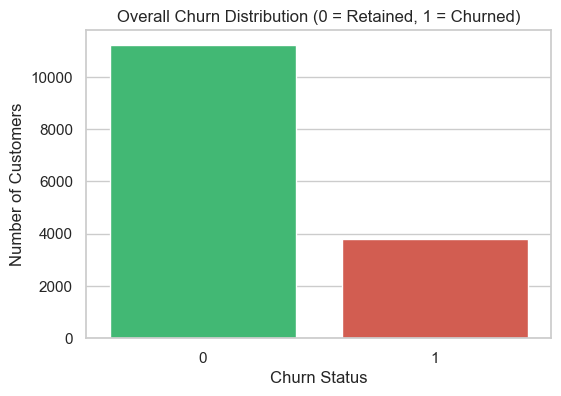

In [122]:
# 1. Overall Churn Distribution Bar Chart

sns.set_theme(style='whitegrid')
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])
plt.title('Overall Churn Distribution (0 = Retained, 1 = Churned)')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.show()
           

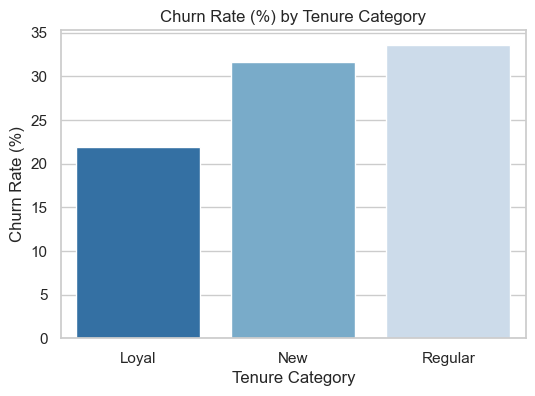

In [124]:
# 2. Churn Rate (%) by Tenure Category Bar Chart

plt.figure(figsize=(6, 4))
tenure_churn = (df.groupby('TenureCategory')['Churn'].mean() * 100).reset_index()
sns.barplot( x='TenureCategory', y='Churn', data=tenure_churn, palette='Blues_r')
plt.title('Churn Rate (%) by Tenure Category')
plt.xlabel('Tenure Category')
plt.ylabel('Churn Rate (%)')
plt.show()

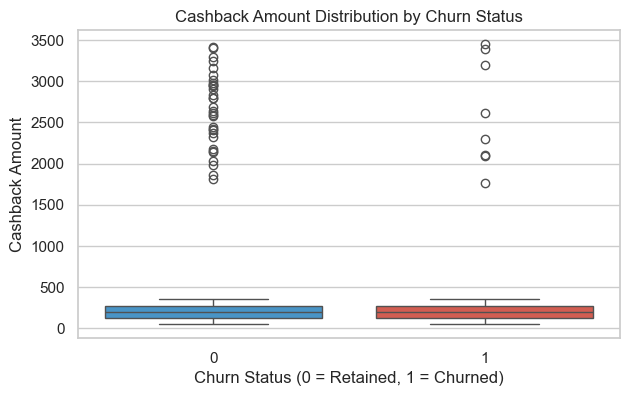

In [125]:
# 3. Cashback Amount vs Churn Status (Boxplot)
plt.figure(figsize=(7, 4))
sns.boxplot(x='Churn', y='CashbackAmount', data=df, palette=['#3498db', '#e74c3c'])
plt.title('Cashback Amount Distribution by Churn Status')
plt.xlabel('Churn Status (0 = Retained, 1 = Churned)')
plt.ylabel('Cashback Amount')
plt.show()

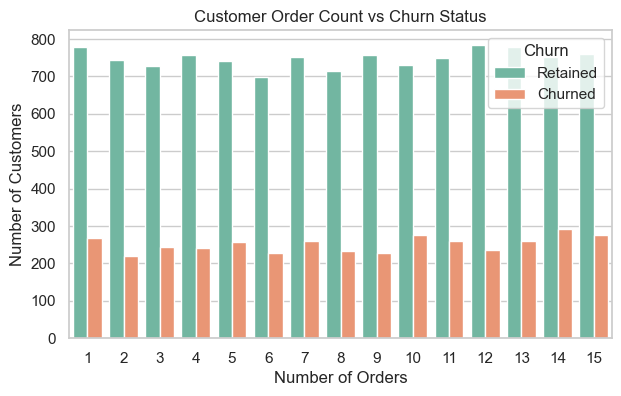

In [127]:
# 4. Order Count vs Churn (Barplot / Countplot)
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='OrderCount', hue='Churn', palette='Set2')
plt.title('Customer Order Count vs Churn Status')
plt.xlabel('Number of Orders')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['Retained', 'Churned'])
plt.show()

In [128]:
print( 'Churn Rate by Gender (in %):\n', df.groupby('Gender')['Churn'].mean() * 100)

Churn Rate by Gender (in %):
 Gender
Female    25.485990
Male      24.890598
Name: Churn, dtype: float64


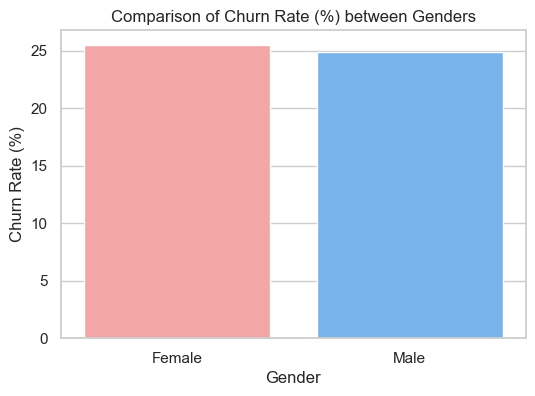

In [129]:
#5. Gender vs Churn Comparison Graph (Bar Chart)

plt.figure(figsize=(6, 4))
gender_churn = (df.groupby('Gender')['Churn'].mean() * 100).reset_index()
sns.barplot(x='Gender', y='Churn', data=gender_churn, palette=['#ff9999', '#66b3ff'])
plt.title('Comparison of Churn Rate (%) between Genders')
plt.xlabel('Gender')
plt.ylabel('Churn Rate (%)')
plt.show()

KPI (Key Performance Indicators)

In [152]:
#1. Overall Summary KPIs

total_customers = len(df)
total_churned = df['Churn'].sum()
total_retained = total_customers - total_churned
overall_churn_rate = (total_churned / total_customers) * 100

print('OVERALL E-COMMERCE KPIs')
print('-' * 50)

print(f' Total Customers : {total_customers}')
print(f' Total Churned : {total_churned}')
print(f' Total Retained : {total_retained}')
print(f' Overall Churn Rate : {overall_churn_rate.round()} % ')

OVERALL E-COMMERCE KPIs
--------------------------------------------------
 Total Customers : 15000
 Total Churned : 3778
 Total Retained : 11222
 Overall Churn Rate : 25.0 % 


In [156]:
#2. Churn Rate by Tenure Category

print('CHURN RATE BY TENURE CATEGORY')
print('-' * 50)

tenure_kpi = (df.groupby('TenureCategory')['Churn'].mean() * 100).round(2)
for category, rate in tenure_kpi.items():
    print(f'{category:10s} : {rate}%')


OVERALL E-COMMERCE KPIs
--------------------------------------------------
Loyal      : 21.86%
New        : 31.6%
Regular    : 33.61%


In [162]:
#3. Churn Rate by Gender

print('CHURN RATE BY GENDER')
print('-' * 50)

gender_kpi = (df.groupby('Gender')['Churn'].mean() * 100).round()
for gender, rate in gender_kpi.items():
    print(f'{gender:10s} : {rate}%')

CHURN RATE BY GENDER
--------------------------------------------------
Female     : 25.0%
Male       : 25.0%


In [161]:
# 4. Churn Rate by Cashback Status

print('CHURN RATE BY CASHBACK STATUS')
print('-' * 50)

cashback_kpi = (df.groupby('IsHighCashback')['Churn'].mean()*100).round()
status_map = {0: 'Low Cashback', 1: 'High Cashback'}
for status, rate in cashback_kpi.items():
    print(f'{status_map[status]:15s} : {rate}%')

CHURN RATE BY CASHBACK STATUS
--------------------------------------------------
Low Cashback    : 25.0%
High Cashback   : 25.0%


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   CustomerID            15000 non-null  object        
 1   SignupDate            15000 non-null  datetime64[ns]
 2   Tenure                15000 non-null  float64       
 3   PreferredLoginDevice  15000 non-null  object        
 4   CityTier              15000 non-null  int64         
 5   WarehouseToHome       15000 non-null  int64         
 6   PreferredPaymentMode  15000 non-null  object        
 7   Gender                15000 non-null  object        
 8   HourSpendOnApp        15000 non-null  int64         
 9   NumberOfAddress       15000 non-null  int64         
 10  SatisfactionScore     15000 non-null  int64         
 11  MaritalStatus         15000 non-null  object        
 12  OrderCount            15000 non-null  int64         
 13  DaySinceLastOrde

In [163]:
# Save the final cleaned and feature-engineered dataset for Power BI
df.to_csv('ecommerce_churn_cleaned_final.csv', index=False)
print( "Success! Final dataset saved successfully as 'ecommerce_churn_cleaned_final.csv'.")
print('Total rows and columns in final dataset:', df.shape)

Success! Final dataset saved successfully as 'ecommerce_churn_cleaned_final.csv'.
Total rows and columns in final dataset: (15000, 20)
